# Practical Session 10 &mdash; A. k-means, and what can go wrong

**Clustering** finds groups in data that comes without answers. Until now every example came with its
answer $y$; here there is no $y$, only the features, and the task is to find **groups of similar
examples**. A good group is *close inside* and *far from the other groups*, and "close" is measured with a
**distance**: the differences in each feature, squared, added up, then the square root.

| | Notebook | What you do |
|---|---|---|
| **A** | **k-means, and what can go wrong** | **k-means by hand, a photo, bad starts, scoring by counting pairs, units (this notebook)** |
| B | How many groups, and clouds | the elbow and the silhouette; Gaussian mixtures and soft memberships |
| C | Crowds, trees, and choosing | DBSCAN and hierarchical clustering by hand; which method for which situation |

There are four ideas of what a group is: the points around a **center** (k-means, here), a **cloud** that can
stretch and tilt (B), a **crowd** of any shape and a **branch** of a tree of merges (C).

> &#11088; **Key idea.** k-means repeats two moves: every point **joins** its nearest center, then every center
> **moves** to the average of its points. Each move can only lower the cost, yet the answer still depends on
> the start, on the units, and on k-means' idea of a group.

The data: eight objects, the rents of eight apartments, three overlapping blobs of points, a photo, twelve
points in three squares, five letters, four made-up 2-D shapes, 178 wines (real data) and 200 customers.

*Run the cells in order (Shift+Enter). Self-contained and offline; the whole notebook runs in about
30 seconds.*

In [1]:
import itertools
from collections import Counter

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.datasets import load_sample_image, load_wine
from sklearn.metrics import adjusted_rand_score
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeRegressor

from nb_utils import use_style
from nb_data import make_customers, make_rent8, make_shapes, make_three_blobs

use_style("notes")
C0, C1, CG, CN = "#0072B2", "#D55E00", "#009E73", "#E69F00"
CP = "#CC79A7"                   # pink, when a fifth color is needed
CX = "0.62"                      # gray, for reference lines
mpl.rcParams["axes.prop_cycle"] = mpl.cycler(color=[C0, C1, CG, CN, CP])   # frozen palette
COLORS = [C0, C1, CG, CN, CP]


def cost_of(X, labels):
    "the cost (WCSS) of ANY grouping: every point's squared distance to its own group's average, added up"
    X = np.asarray(X, dtype=float).reshape(len(X), -1)
    return sum(((X[labels == k] - X[labels == k].mean(axis=0)) ** 2).sum() for k in np.unique(labels))


def best_renaming(truth, found, relabel=False):
    '''how many points land in their true group, under the best renaming of the found groups
    (with relabel=True: the found groups renamed that way, so their colors match the truth)'''
    names, targets = np.unique(found), np.unique(truth).tolist()
    targets += [max(targets) + 1 + i for i in range(len(names) - len(targets))]   # spare names: more found groups than true ones
    perm = max(itertools.permutations(targets, len(names)),
               key=lambda p: sum(np.sum((found == a) & (truth == b)) for a, b in zip(names, p)))
    if relabel:
        return np.select([found == a for a in names], perm)
    return sum(np.sum((found == a) & (truth == b)) for a, b in zip(names, perm))


def territories(ax, centers, lim, colors=COLORS):
    "paint each center's territory (where it is the nearest center) and the borders between them"
    (x0, x1), (y0, y1) = lim
    g1, g2 = np.meshgrid(np.linspace(x0, x1, 300), np.linspace(y0, y1, 300))
    grid = np.c_[g1.ravel(), g2.ravel()]
    near = ((grid[:, None, :] - centers[None]) ** 2).sum(axis=2).argmin(axis=1).reshape(g1.shape)
    K = len(centers)
    ax.contourf(g1, g2, near, levels=np.arange(K + 1) - 0.5, colors=colors[:K], alpha=0.13)
    ax.contour(g1, g2, near, levels=np.arange(K) + 0.5, colors="0.3", linewidths=1.0)
    ax.set_xlim(x0, x1); ax.set_ylim(y0, y1)


print("ready")

ready


## 1. Let's start with a sort

**Your turn first (1 minute).** Split these eight objects into **two groups**. Nobody tells you what the
groups should be.

| | 1 | 2 | 3 | 4 | 5 | 6 | 7 | 8 |
|---|---|---|---|---|---|---|---|---|
| shape | circle | circle | circle | circle | square | square | square | square |
| color | blue | blue | orange | orange | blue | blue | orange | orange |
| size | small | large | small | large | small | large | small | large |

By **color**, by **shape**, by **size**: three different answers, and all three are right. They also have
nothing in common: each color group holds two circles and two squares, two small objects and two large ones.
The groups depend on what you look at, and there is no answer key. That is clustering. (How to measure
"nothing in common" with one number comes in &sect;7.)

## 2. By hand: the eight apartments

**The k-means idea.** Choose $K$, the number of groups, and put $K$ **centers** somewhere (for instance at $K$
random points). Then repeat two moves until no point changes group:

1. **join**: every point joins its **nearest** center;
2. **move**: every center moves to the **average** of its points.

Think of $K$ pizzerias opening in a new town: every customer goes to the nearest one, then every pizzeria moves
to the middle of its customers, and again, until nobody switches.

Our data: eight apartments with their area and their rent (in hundreds of euros): 2, 3, 4, 5, 10, 11, 12, 13.
k-means gets **only the rents**: no areas, no labels. $K=2$, and we start the two centers at 0 and 9 (picked to
keep the arithmetic clean). The function `lloyd` below writes the two moves out; the cell prints every pass,
then checks the result with scikit-learn's `KMeans` started from the same centers.

**Your turn first (2 minutes):** which center is nearest to each rent? Then, with the centers at 3 and 10.2,
which rent changes sides?

pass 1: centers 0 and 9, border 4.5 -> groups [2, 3, 4] | [5, 10, 11, 12, 13]; the centers move to 3 and 10.2
pass 2: centers 3 and 10.2, border 6.6 -> groups [2, 3, 4, 5] | [10, 11, 12, 13]; the centers move to 3.5 and 11.5
pass 3: border 7.5, nobody changes group -> stop
(before pass 2, rent 5 is 2 from 3 and 5.2 from 10.2)

scikit-learn from the same start: centers 3.5 and 11.5, cost 10


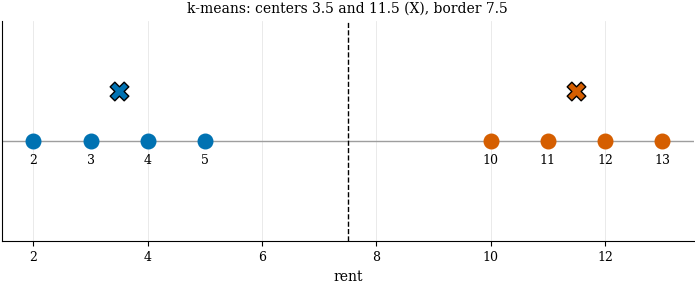

In [2]:
area, rents = make_rent8()                   # area in tens of m^2 (k-means does not see it), rent in 100 EUR
START = [0.0, 9.0]                           # <-- CHANGE ME: the two starting centers


def lloyd(X, centers, max_passes=100):
    '''k-means by hand. Each pass: JOIN (every point to its nearest center; a tie goes to the first
    one), then MOVE (every center to the average of its points; a center with no points stays where
    it is). Stops when no point changes group. Returns the labels, the centers, the cost after every
    half-step, and each pass's (centers before, groups, centers after).'''
    X = np.asarray(X, dtype=float).reshape(len(X), -1)
    centers = np.array(centers, dtype=float).reshape(-1, X.shape[1])
    costs, passes, labels = [], [], None
    for _ in range(max_passes):
        d2 = ((X[:, None, :] - centers[None, :, :]) ** 2).sum(axis=2)     # squared distances
        joined = d2.argmin(axis=1)                                        # join
        costs.append(d2[np.arange(len(X)), joined].sum())
        if labels is not None and np.array_equal(joined, labels):
            break                                                         # nobody changed group: stop
        labels, before = joined, centers.copy()
        for k in range(len(centers)):                                     # move
            if (labels == k).any():
                centers[k] = X[labels == k].mean(axis=0)
        costs.append(((X - centers[labels]) ** 2).sum())
        passes.append((before, labels.copy(), centers.copy()))
    return labels, centers, costs, passes


labels, centers, costs, passes = lloyd(rents, START)
for p, (before, groups, after) in enumerate(passes, start=1):
    members = [rents[groups == k].astype(int).tolist() for k in range(len(before))]
    print(f"pass {p}: centers {before[0, 0]:g} and {before[1, 0]:g}, border {before.mean():g} -> "
          f"groups {members[0]} | {members[1]}; the centers move to {after[0, 0]:g} and {after[1, 0]:g}")
print(f"pass {len(passes) + 1}: border {centers.mean():g}, nobody changes group -> stop")
if len(passes) > 1:                          # where rent 5 stands before pass 2
    c2 = passes[1][0].ravel()
    print(f"(before pass 2, rent 5 is {abs(5 - c2[0]):g} from {c2[0]:g} and {abs(5 - c2[1]):g} from {c2[1]:g})")

km = KMeans(n_clusters=2, init=np.array(START)[:, None], n_init=1).fit(rents[:, None])
low, high = sorted(km.cluster_centers_.ravel())
print(f"\nscikit-learn from the same start: centers {low:g} and {high:g}, cost {km.inertia_:g}")

fig, ax = plt.subplots(figsize=(7.0, 2.9))
ax.axhline(0, color=CX, lw=1)
for k in range(2):
    ax.scatter(rents[labels == k], np.zeros((labels == k).sum()), s=110, color=COLORS[k], zorder=3)
    ax.scatter(centers[k], 0.5, marker="X", s=180, color=COLORS[k], edgecolor="k", zorder=4)
ax.axvline(centers.mean(), color="k", ls="--", lw=1)
for r in rents:
    ax.annotate(f"{r:g}", (r, 0), (0, -16), textcoords="offset points", ha="center", fontsize=9)
ax.set_ylim(-1, 1.2); ax.set_yticks([]); ax.set_xlabel("rent")
ax.set_title(f"k-means: centers {centers[0, 0]:g} and {centers[1, 0]:g} (X), border {centers.mean():g}",
             fontsize=10)
plt.show()

**What happened.** Pass 1: the border is halfway between the centers, at 4.5, so 2, 3 and 4 join the center at
0 and every rent from 5 up joins the center at 9; the centers move to the averages, 3 and 10.2. Pass 2: rent 5
changes sides (it is 2 from 3 but 5.2 from 10.2), and the centers move to 3.5 and 11.5. Pass 3: the border is
7.5, nobody changes sides, and k-means stops. scikit-learn lands on the same centers.

### What k-means is minimizing

Every point pays the squared distance to its own center, and the bill is added up: the **cost**
(scikit-learn's `inertia_`, also called the WCSS, the within-cluster sum of squares). The cell prints the cost
after every half-step of the run above, the cost of ONE center for all eight rents wherever it sits, and a
one-question tree that is *told the areas*.

**Predict first:** can a join or a move ever raise the cost?

the cost after every half-step (join, move, join, ...):

 75 -> 40.8 -> 17.76 -> 10 -> 10
one center at 6   costs 156
one center at 7   costs 140
one center at 7.5 costs 138
one center at 8   costs 140
one center at 9   costs 156
the average of the eight rents is 7.5

a one-question tree on (area -> rent): cut at area 4.5, predictions 3.5 and 11.5, cost 10


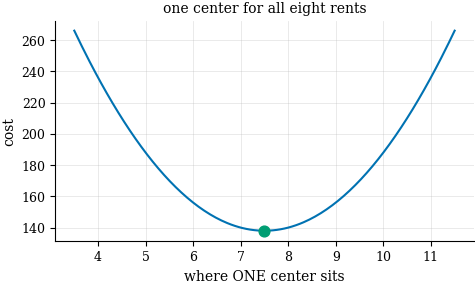

In [3]:
print("the cost after every half-step (join, move, join, ...):", " -> ".join(f"{c:g}" for c in costs))

# what the cost measures: ONE center c for all eight rents costs sum (rent - c)^2
for c in (6, 7, 7.5, 8, 9):
    print(f"one center at {c:<3g} costs {((rents - c) ** 2).sum():g}")
print(f"the average of the eight rents is {rents.mean():g}")

# k-means never saw the areas. A one-question tree that IS told the areas, and predicts the rent:
stump = DecisionTreeRegressor(max_depth=1).fit(area[:, None], rents)
leaves = np.unique(stump.predict(area[:, None]))
print(f"\na one-question tree on (area -> rent): cut at area {stump.tree_.threshold[0]:g}, predictions "
      f"{leaves[0]:g} and {leaves[1]:g}, cost {((rents - stump.predict(area[:, None])) ** 2).sum():g}")

fig, ax = plt.subplots(figsize=(4.8, 2.9))
cs = np.linspace(3.5, 11.5, 200)
ax.plot(cs, [((rents - c) ** 2).sum() for c in cs], color=C0)
ax.scatter([rents.mean()], [((rents - rents.mean()) ** 2).sum()], s=60, color=CG, zorder=3)
ax.set_xlabel("where ONE center sits"); ax.set_ylabel("cost")
ax.set_title("one center for all eight rents", fontsize=10)
plt.show()

**What happened.** The cost fell 75 &rarr; 40.8 &rarr; 17.76 &rarr; 10 &rarr; 10. Why does the *average*
matter? One center for all eight rents is cheapest at their average, 7.5 (cost 138), and dearer the farther it
sits (140 at 7 or 8, 156 at 6 or 9). So a **move** to the average can only lower the cost, and so can a
**join** (every point picks its nearest center). The cost never goes up, and since there are only finitely many
ways to split eight rents, k-means must stop.

> **Going deeper.** $\text{cost} = \sum_k \sum_{i \in \text{group } k} \lVert x_i - c_k\rVert^2$. For one group,
> $\sum_i (x_i - c)^2$ is smallest where its slope $-2\sum_i (x_i - c)$ is zero: at $c$ = the average.

And the last line: a tree that is *told the areas* and predicts the rent with one question cuts at area 4.5 and
predicts 3.5 and 11.5, at cost 10. k-means never saw the areas, yet it found the same two groups at the same
cost.

## 3. Watch it learn

Now 420 points in three overlapping blobs, and three centers that start badly placed, all below the data.
Every pass prints the cost after the join and after the move; the pictures show four moments, with each
center's **territory** (where it is the nearest center) painted in its color. The borders between territories
are straight lines, halfway between two centers. In each picture the dots keep the color of the group they
joined; the X marks and the painted territories show the centers *after* the move, so a dot in another center's
territory is one that switches at the next join.

7 passes change something, then pass 8 changes nothing: stop
cost after every half-step: 12648, 1770, 1598, 1430, 1255, 1069, 988, 952, 940, 932, 929, 928, 927, 927, 927
scikit-learn from the same start: cost 926.86; same groups: True
after pass 1: 79 dots sit in another center's territory; the next join moves 79
after pass 3: 34 dots sit in another center's territory; the next join moves 34


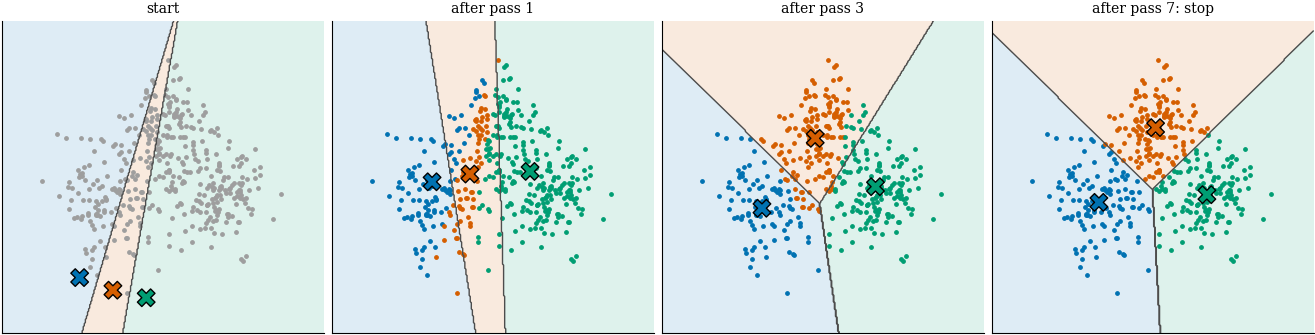

In [3]:
X3, y3 = make_three_blobs()
BAD_START = np.array([[-4.0, -3.0], [-2.5, -3.5], [-1.0, -3.8]])
labels3, centers3, costs3, passes3 = lloyd(X3, BAD_START)
print(f"{len(passes3)} passes change something, then pass {len(passes3) + 1} changes nothing: stop")
print("cost after every half-step:", ", ".join(f"{c:.0f}" for c in costs3))
km3 = KMeans(n_clusters=3, init=BAD_START, n_init=1).fit(X3)
print(f"scikit-learn from the same start: cost {km3.inertia_:.2f}; same groups: "
      f"{adjusted_rand_score(labels3, km3.labels_) == 1.0}")
for p in (1, 3):                             # after a move, some dots sit in another center's territory
    _, groups, after = passes3[p - 1]
    nearest = ((X3[:, None, :] - after[None]) ** 2).sum(axis=2).argmin(axis=1)
    print(f"after pass {p}: {np.sum(nearest != groups)} dots sit in another center's territory; "
          f"the next join moves {np.sum(passes3[p][1] != groups)}")

lim = ((-7.5, 7.0), (-5.2, 7.2))
fig, axes = plt.subplots(1, 4, figsize=(13.2, 3.4))
shown = [("start", BAD_START, None), ("after pass 1", passes3[0][2], passes3[0][1]),
         ("after pass 3", passes3[2][2], passes3[2][1]), (f"after pass {len(passes3)}: stop", centers3, labels3)]
for ax, (title, C, lab) in zip(axes, shown):
    territories(ax, C, lim)
    if lab is None:
        ax.scatter(*X3.T, s=6, color=CX)
    else:
        for k in range(3):
            ax.scatter(*X3[lab == k].T, s=6, color=COLORS[k])
    ax.scatter(*C.T, marker="X", s=160, color=COLORS[:3], edgecolor="k", zorder=4)
    ax.set_title(title, fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.show()

The cost drops fast at first (12648, then 1770), then more slowly, and the last passes barely move it (929,
928, 927); it never goes up. After 7 passes nothing changes, and the eighth pass stops it. scikit-learn, started
at the same three points, finds the same groups. After pass 1, 79 dots sit in another center's territory, and
the next join moves exactly those 79; after pass 3, 34. Every border is straight, a fact that matters in &sect;8.

## 4. Real data: a photo with 96,615 colors

Every pixel of a photo is three numbers: red, green, blue (8 bits each, 24 bits per pixel). k-means can group
those **colors** into $K$ groups and repaint every pixel with its group's center, so the photo uses only $K$
colors. (We fit k-means on 10,000 random pixels, then give every pixel the color of its nearest center.)

**Predict first:** how many colors before you stop noticing?

the photo: 427 x 640 = 273,280 pixels, 96,615 different colors
K =  2:  0 reddish colors in the palette; each pixel stores a 1-bit color number instead of 24 bits: 24 times smaller
K =  4:  0 reddish colors in the palette; each pixel stores a 2-bit color number instead of 24 bits: 12 times smaller
K = 16:  3 reddish colors in the palette; each pixel stores a 4-bit color number instead of 24 bits: 6 times smaller
K = 64: 13 reddish colors in the palette; each pixel stores a 6-bit color number instead of 24 bits: 4 times smaller


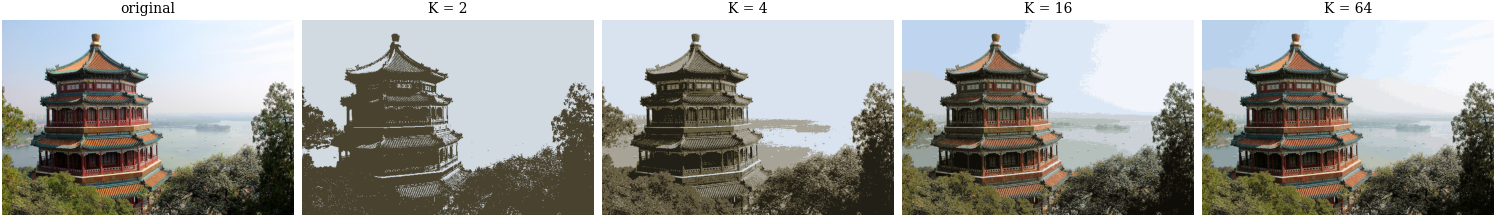

In [4]:
photo = load_sample_image("china.jpg")
pixels = photo.reshape(-1, 3).astype(float)
print(f"the photo: {photo.shape[0]} x {photo.shape[1]} = {len(pixels):,} pixels, "
      f"{len(np.unique(pixels, axis=0)):,} different colors")

K_LIST = (2, 4, 16, 64)                      # <-- CHANGE ME: how many colors to keep
rng = np.random.default_rng(0)
sample = pixels[rng.choice(len(pixels), 10_000, replace=False)]
fig, axes = plt.subplots(1, len(K_LIST) + 1, figsize=(3.0 * (len(K_LIST) + 1), 2.6))
axes[0].imshow(photo); axes[0].set_title("original", fontsize=10)
for ax, K in zip(axes[1:], K_LIST):
    km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(sample)
    palette = km.cluster_centers_
    repainted = palette[km.predict(pixels)].reshape(photo.shape)
    reddish = np.sum((palette[:, 0] > palette[:, 1] + 30) & (palette[:, 0] > palette[:, 2] + 30))
    bits = np.ceil(np.log2(K))               # numbering K colors takes a whole number of bits
    print(f"K = {K:2d}: {reddish:2d} reddish colors in the palette; each pixel stores a {bits:g}-bit color "
          f"number instead of 24 bits: {24 / bits:g} times smaller")
    ax.imshow(np.clip(repainted, 0, 255).astype(np.uint8))
    ax.set_title(f"K = {K}", fontsize=10)
for ax in axes:
    ax.axis("off")
plt.show()

$K=2$: just light and dark, a two-tone poster. $K=4$: no red left at all (0 reddish colors in the palette).
$K=16$: the red-orange roofs are back (3 reddish colors), and each pixel stores a 4-bit color number instead of
24 bits, 6 times smaller than the raw bitmap. $K=64$: close to the original, 4 times smaller. Here $K$ is a
trade-off between quality and size, not a "true" number of groups.

*Photo: danielbuechele on Flickr, CC BY 2.0 (https://creativecommons.org/licenses/by/2.0/), as distributed with
scikit-learn (`china.jpg`); colors reduced with k-means.*

## 5. Bad starts: a local minimum

**Check yourself.** You run k-means twice on the same data, with the same $K$, and get two **different**
groupings. Is it a bug?

The data: twelve points in three squares. The first lines run scikit-learn's k-means twice with random
starts (one start each, two seeds). Then `lloyd` runs from two hand-picked starts: start A puts one center in
each square, start B puts two centers in the same square. Last, it tries **every** start that uses three of
the twelve points as centers.

one random start (seed 0): cost 24.00
one random start (seed 6): cost 221.33
start A: cost 24 by hand, 24 with scikit-learn
start B: cost 216 by hand, 216 with scikit-learn

all 220 starts (three of the twelve points as centers): where k-means stops
   cost   24.00: 188 starts
   cost  216.00:   8 starts
   cost  220.00:  10 starts
   cost  221.33:   6 starts
   cost  270.00:   5 starts
   cost  271.33:   2 starts
   cost  274.00:   1 starts
   -> 188 starts find 24, 32 get stuck


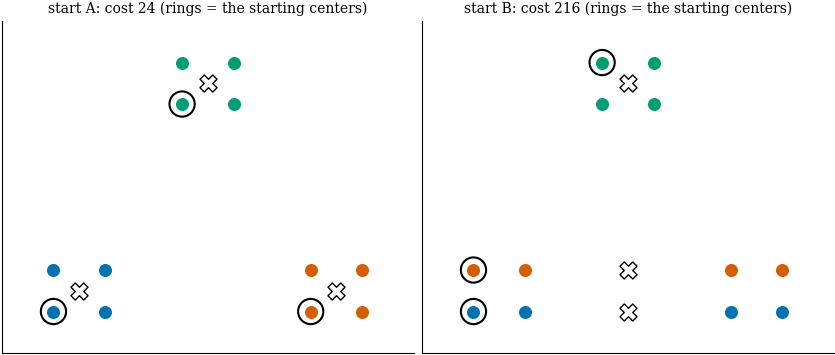

In [6]:
X12 = np.array([(0, 0), (0, 2), (2, 0), (2, 2), (10, 0), (10, 2), (12, 0), (12, 2),
                (5, 10), (5, 12), (7, 10), (7, 12)], dtype=float)
for seed in (0, 6):                          # <-- CHANGE ME: other seeds, other runs
    run = KMeans(n_clusters=3, init="random", n_init=1, random_state=seed).fit(X12)
    print(f"one random start (seed {seed}): cost {run.inertia_:.2f}")

STARTS = {"start A": (0, 4, 8), "start B": (0, 1, 9)}
results = {}
for name, idx in STARTS.items():
    lab, cen, cst, _ = lloyd(X12, X12[list(idx)])
    sk = KMeans(n_clusters=3, init=X12[list(idx)], n_init=1).fit(X12)
    results[name] = (idx, lab, cen)
    print(f"{name}: cost {cst[-1]:g} by hand, {sk.inertia_:g} with scikit-learn")

tally = Counter()                                      # where k-means stops, start by start
for start in itertools.combinations(range(12), 3):     # every choice of 3 of the 12 points as centers
    _, _, costs_t, _ = lloyd(X12, X12[list(start)])
    tally[round(costs_t[-1], 2)] += 1                  # the cost where this start stops
print(f"\nall {sum(tally.values())} starts (three of the twelve points as centers): where k-means stops")
for cost, n in sorted(tally.items()):
    print(f"   cost {cost:7.2f}: {n:3d} starts")
stuck = sum(n for c, n in tally.items() if c > 24.5)
print(f"   -> {tally[24.0]} starts find 24, {stuck} get stuck")

fig, axes = plt.subplots(1, 2, figsize=(8.4, 3.6))
for ax, (name, (idx, lab, cen)) in zip(axes, results.items()):
    for k in range(3):
        ax.scatter(*X12[lab == k].T, s=70, color=COLORS[k], zorder=3)
    ax.scatter(*X12[list(idx)].T, s=330, facecolor="none", edgecolor="k", lw=1.5, zorder=4)
    ax.scatter(*cen.T, marker="X", s=150, color="white", edgecolor="k", zorder=5)
    ax.set_title(f"{name}: cost {cost_of(X12, lab):g} (rings = the starting centers)", fontsize=10)
    ax.set_xlim(-2, 14); ax.set_ylim(-2, 14); ax.set_xticks([]); ax.set_yticks([])
plt.show()

**No, it is not a bug.** One random start found the three squares (cost 24), the other stopped at cost 221.33.
Start A finds the squares: cost 24, the best possible. Start B splits the points by rows: cost 216, nine times
worse, and it is **stuck**: every point is already with its nearest center and every center at its group's
average, so no move can lower the cost. Like a hiker in fog who stops in the first valley: every step from here
goes up, yet a valley nine times deeper exists elsewhere.

Of the 220 starts, 188 find 24 and 32 get stuck somewhere: about 1 start in 7. (One start, the one that costs
274, empties a center along the way; our `lloyd` leaves an empty center where it is, scikit-learn moves it
somewhere useful, so there that start ends at 24.)

## 6. The cure: restart, and start cleverly

Two cures. **Restart:** run k-means from several starts and keep the one with the lowest cost. If 1 start in 7
gets stuck, all ten of ten independent starts get stuck very rarely. **Start cleverly:** *k-means++* picks each
new starting center at random, but points far from the centers chosen so far are likelier: it draws a point
with probability proportional to its squared distance to the nearest chosen center. The cell checks both, and
shows what scikit-learn does by default. (This cell takes about 20 seconds: it fits k-means more than a
thousand times.)

In [7]:
p_stuck = 1 - tally[24.0] / 220
print(f"one start gets stuck with probability {p_stuck:.4f} (about 1 in {1 / p_stuck:.0f}); "
      f"ten starts all stuck: {p_stuck ** 10:.1e}")
N_SEEDS = 1000                               # <-- CHANGE ME: how many runs to try (the time grows with it)
one_start = np.mean([KMeans(3, init="random", n_init=1, random_state=s).fit(X12).inertia_ > 24.5
                     for s in range(N_SEEDS)])
ten_starts = sum(KMeans(3, init="random", n_init=10, random_state=s).fit(X12).inertia_ > 24.5
                 for s in range(100))
print(f"scikit-learn with random starts: one start is stuck in {one_start:.1%} of {N_SEEDS} runs; "
      f"ten starts (keep the cheapest) in {ten_starts} of 100 runs")

# k-means++ by hand: the first center is the bottom-left point (0, 0); where does the second one land?
d2 = ((X12 - X12[0]) ** 2).sum(axis=1)                 # squared distance of every point to (0, 0)
same = d2[1:4].sum() / d2.sum()                        # points 1-3 share its square
print(f"\nk-means++, second center in the same square: {d2[1:4].sum():g} / {d2.sum():g} = {same:.1%}"
      f"   (a blind pick: 3/11 = {3 / 11:.0%})")
draws = np.random.default_rng(0).choice(12, size=100_000, p=d2 / d2.sum())
print(f"simulated with 100,000 draws: {np.isin(draws, [1, 2, 3]).mean():.1%}")

# scikit-learn's default: ONE k-means++ start. It can still miss: the eight rents with K = 4
print(f"\nKMeans().n_init = {KMeans().n_init!r}: by default scikit-learn starts only once")
best4 = 2.0                                            # the best cost for the rents with K = 4
for n_init, seeds in (("auto", 100), (10, 100), (50, 20)):
    miss = sum(KMeans(4, n_init=n_init, random_state=s).fit(rents[:, None]).inertia_ > best4 + 1e-9
               for s in range(seeds))
    print(f"the rents with K = 4, n_init = {n_init!r:6}: misses the best grouping on {miss} of {seeds} seeds")

one start gets stuck with probability 0.1455 (about 1 in 7); ten starts all stuck: 4.2e-09


scikit-learn with random starts: one start is stuck in 14.6% of 1000 runs; ten starts (keep the cheapest) in 0 of 100 runs

k-means++, second center in the same square: 16 / 1148 = 1.4%   (a blind pick: 3/11 = 27%)
simulated with 100,000 draws: 1.4%

KMeans().n_init = 'auto': by default scikit-learn starts only once


the rents with K = 4, n_init = 'auto': misses the best grouping on 83 of 100 seeds


the rents with K = 4, n_init = 10    : misses the best grouping on 12 of 100 seeds


the rents with K = 4, n_init = 50    : misses the best grouping on 0 of 20 seeds


With random starts, one start gets stuck in 14.6% of 1,000 runs on the twelve points, as the 220 starts
predicted (0.1455, about 1 in 7); ten starts, keeping the cheapest, were stuck in 0 of 100 runs, and all ten
stuck at once has a probability of about 4 in a billion (4.2e-09). k-means++ makes a bad start much less
likely: after a first center at the bottom-left point, the second lands in the same square only 1.4% of the
time, against 27% for a blind pick (the simulation agrees). scikit-learn's version is more careful still: it
tries a few candidates for every new center and keeps the best one.

But scikit-learn's `KMeans` starts only **once** by default (`n_init="auto"`), and even k-means++ can miss: on
the eight rents with $K = 4$ one start misses the best grouping on 83 of 100 seeds, ten starts on 12, and fifty
starts on 0 of 20. **Ask for several starts: `n_init=10`.** From here on every k-means gets `n_init` and a fixed
`random_state`.

## 7. Did it find the right groups?

To test a method, we use data where we **secretly know** the true groups (in real use there is no key). The
names of the groups are arbitrary: a method can find exactly the right groups and call them the other way round.
So we compare **pairs** of points: together in both groupings, or apart in both? The **ARI** (adjusted Rand
index) turns that into one number: 1 = the same grouping, 0 = what a random grouping gets.

**Your turn first (3 minutes).** Five letters, true groups {A, B, C} and {D, E}; a method found {A, B} and
{C, D, E}. Five letters give 10 pairs (AB, AC, ..., DE). For each pair: together in both groupings, or apart in
both? How many of the 10 agree?

In [8]:
letters = "ABCDE"
truth = np.array([0, 0, 0, 1, 1])                       # {A, B, C} | {D, E}
swapped = 1 - truth                                     # the same groups, names swapped
print(f"names swapped: letter by letter {np.mean(truth == swapped):.0%} match, "
      f"ARI {adjusted_rand_score(truth, swapped):g}\n")

found = np.array([0, 0, 1, 1, 1])                       # <-- CHANGE ME: {A, B} | {C, D, E}; try [0, 1, 2, 2, 2]


def pair_agreement(a, b):
    "the share of pairs on which two groupings agree (together in both, or apart in both)"
    return np.mean([(a[i] == a[j]) == (b[i] == b[j]) for i, j in itertools.combinations(range(len(a)), 2)])


for i, j in itertools.combinations(range(5), 2):
    t, f = truth[i] == truth[j], found[i] == found[j]
    print(f"{letters[i]}{letters[j]}: {'together' if t else 'apart':8s} in the truth, "
          f"{'together' if f else 'apart':8s} in the found groups  {'agree' if t == f else ''}")
agree = pair_agreement(truth, found)
# chance: the average agreement over every regrouping of the five letters with the same group sizes
regroupings = sorted(set(itertools.permutations(found.tolist())))   # every shuffle of the found labels
chance = np.mean([pair_agreement(truth, np.array(g)) for g in regroupings])
print(f"\n{agree * 10:.0f} of 10 pairs agree ({agree:.2f}); a random regrouping with the same sizes agrees on "
      f"{chance:.2f} on average ({len(regroupings)} regroupings)")
print(f"ARI by hand: ({agree:.2f} - {chance:.2f}) / (1 - {chance:.2f}) = {(agree - chance) / (1 - chance):.4f}; "
      f"scikit-learn: {adjusted_rand_score(truth, found):.4f}")
print(f"letter by letter (best renaming): {best_renaming(truth, found)} of 5 right")

# the opening's three sorts of the eight objects, scored against each other
shape = np.array([0, 0, 0, 0, 1, 1, 1, 1]); color = np.array([0, 0, 1, 1, 0, 0, 1, 1])
size = np.array([0, 1, 0, 1, 0, 1, 0, 1])
for (n1, a), (n2, b) in itertools.combinations((("shape", shape), ("color", color), ("size", size)), 2):
    print(f"the sort by {n1} against the sort by {n2}: ARI {adjusted_rand_score(a, b):.2f}")

names swapped: letter by letter 0% match, ARI 1

AB: together in the truth, together in the found groups  agree
AC: together in the truth, apart    in the found groups  
AD: apart    in the truth, apart    in the found groups  agree
AE: apart    in the truth, apart    in the found groups  agree
BC: together in the truth, apart    in the found groups  
BD: apart    in the truth, apart    in the found groups  agree
BE: apart    in the truth, apart    in the found groups  agree
CD: apart    in the truth, together in the found groups  
CE: apart    in the truth, together in the found groups  
DE: together in the truth, together in the found groups  agree

6 of 10 pairs agree (0.60); a random regrouping with the same sizes agrees on 0.52 on average (10 regroupings)
ARI by hand: (0.60 - 0.52) / (1 - 0.52) = 0.1667; scikit-learn: 0.1667
letter by letter (best renaming): 4 of 5 right
the sort by shape against the sort by color: ARI -0.17
the sort by shape against the sort by size: ARI -0.17
th

6 of 10 pairs agree: AB and DE (together in both); AD, AE, BD and BE (apart in both). A random regrouping with
the same sizes (2 and 3) agrees on 0.52 of the pairs on average, and the ARI rescales so that this counts as 0:
$(0.60 - 0.52)/(1 - 0.52) = 0.17$, exactly scikit-learn's `adjusted_rand_score`. Yet 4 of 5 letters are "right":
**the ARI is strict, and it is not a percentage.** The opening's three sorts score $-0.17$ against each other:
below 0, they agree on fewer pairs than random regroupings would. They really have nothing in common.

> **Going deeper.** $\text{ARI} = \dfrac{\text{agreement} - \text{chance}}{1 - \text{chance}}$, where chance is
> the agreement a random grouping with the same group sizes gets on average.

## 8. What k-means assumes

The same k-means, with the right $K$, on four made-up shapes whose true groups we know: round blobs, two moons,
three tilted clouds, and a small group beside a big one. First the four shapes, with their true groups.

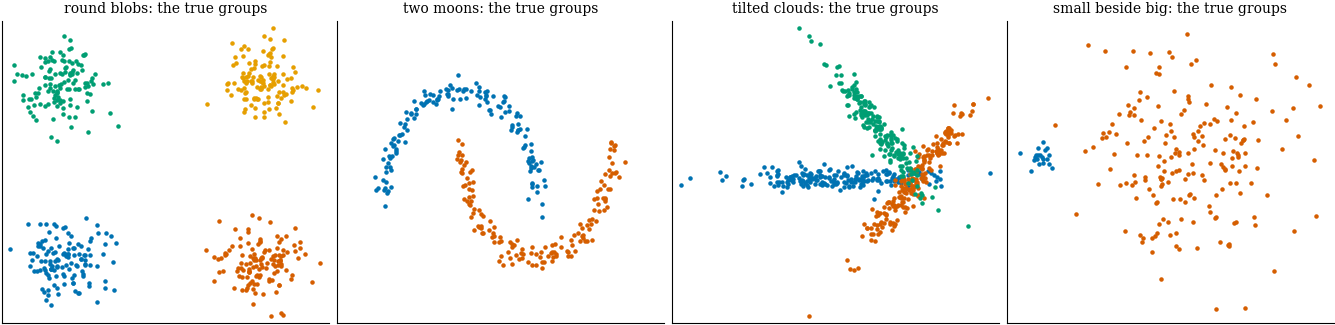

In [9]:
shapes = make_shapes()
names = ["round blobs", "two moons", "tilted clouds", "small beside big"]
fig, axes = plt.subplots(1, 4, figsize=(13.4, 3.3))
for ax, name in zip(axes, names):
    X, y = shapes[name]
    for k in np.unique(y):
        ax.scatter(*X[y == k].T, s=5, color=COLORS[k])
    ax.set_xlim(X[:, 0].min() - 0.5, X[:, 0].max() + 0.5); ax.set_ylim(X[:, 1].min() - 0.5, X[:, 1].max() + 0.5)
    ax.set_title(f"{name}: the true groups", fontsize=10); ax.set_xticks([]); ax.set_yticks([])
plt.show()

**Predict first:** k-means, with the right $K$, on these four shapes: which ones will it get right? The next
cell paints each final center's territory, and colors k-means' groups like the true groups they match best.

round blobs       ARI 1.00 (500 of 500 points in the right group); cost of k-means' groups  1634.5, of the true groups  1634.5
two moons         ARI 0.23 (223 of 300 points in the right group); cost of k-means' groups   121.7, of the true groups   182.9
tilted clouds     ARI 0.36 (444 of 600 points in the right group); cost of k-means' groups  3309.1, of the true groups  5267.0


small beside big  ARI 0.21 (168 of 220 points in the right group); cost of k-means' groups  1254.1, of the true groups  1512.2

a coin flip for each of the 300 moon points: 155 'right', ARI -0.002


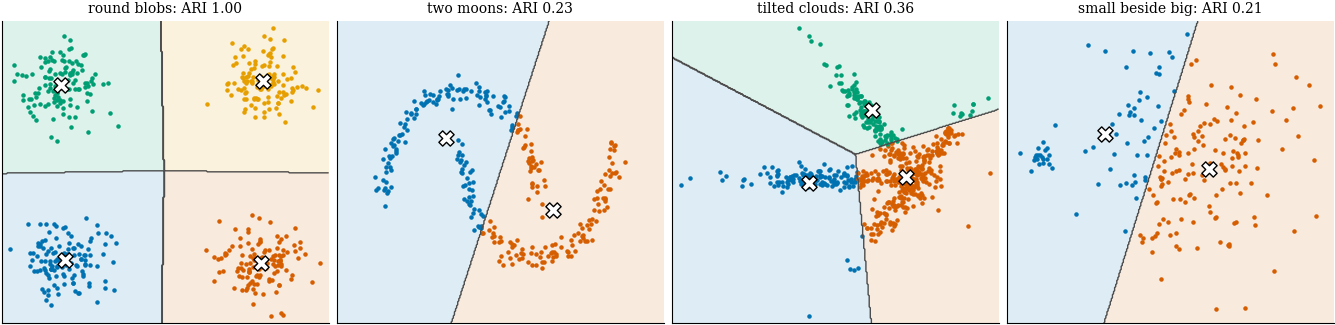

In [10]:
fig, axes = plt.subplots(1, 4, figsize=(13.4, 3.3))
for ax, name in zip(axes, names):
    X, y = shapes[name]
    K = len(np.unique(y))
    km = KMeans(n_clusters=K, n_init=10, random_state=0).fit(X)
    right = best_renaming(y, km.labels_)
    print(f"{name:17s} ARI {adjusted_rand_score(y, km.labels_):.2f} ({right} of {len(y)} points in the right "
          f"group); cost of k-means' groups {km.inertia_:7.1f}, of the true groups {cost_of(X, y):7.1f}")
    lim = ((X[:, 0].min() - 0.5, X[:, 0].max() + 0.5), (X[:, 1].min() - 0.5, X[:, 1].max() + 0.5))
    lab = best_renaming(y, km.labels_, relabel=True)               # renamed so the colors match the truth
    color_of = [COLORS[lab[km.labels_ == k][0]] for k in range(K)]  # each center's color
    territories(ax, km.cluster_centers_, lim, colors=color_of)
    for k in range(K):
        ax.scatter(*X[lab == k].T, s=5, color=COLORS[k])
    ax.scatter(*km.cluster_centers_.T, marker="X", s=120, color="white", edgecolor="k", zorder=4)
    ax.set_title(f"{name}: ARI {adjusted_rand_score(y, km.labels_):.2f}", fontsize=10)
    ax.set_xticks([]); ax.set_yticks([])

Xm, ym = shapes["two moons"]
coin = np.random.default_rng(0).integers(0, 2, len(ym))       # a coin flip for every moon point
print(f"\na coin flip for each of the {len(ym)} moon points: {best_renaming(ym, coin)} 'right', "
      f"ARI {adjusted_rand_score(ym, coin):.3f}")
plt.show()

Round blobs: perfect (1.00). Two moons: 223 of the 300 points land in the right moon, yet ARI 0.23: a coin flip
for every point already gets 155 of 300 "right" (ARI $-0.002$), so half right is what chance gives two groups.
Tilted clouds 0.36, small beside big 0.21 (the big group is cut in two).

Why? The border between two centers is the **straight line** halfway between them (the rents' 4.5, now in
2-D), so every k-means group has straight sides, and a moon has a dent. And k-means is not a bad optimizer
here: on the moons its groups cost **less** than the true groups (121.7 against 182.9). Its cost prefers round
groups of similar size, in comparable units, and more restarts cannot help.

## 9. Units matter, by hand

Four of the eight objects, measured by two numbers: (corners, diameter), corners 0 (circle) or 4 (square),
diameter 2 or 4 cm. The cell tries **every** way to split the four into two groups and prints the cost of each,
first in cm, then with the diameters in mm, then **standardized** (each feature minus its average, divided by
its spread: what scikit-learn's `StandardScaler` does).

**Predict first:** we write the diameters in mm. Do the groups change?

In [5]:
four = np.array([[0, 2], [0, 4], [4, 2], [4, 4]], dtype=float)     # small circle, large circle, small square, large square
names4 = ["small circle", "large circle", "small square", "large square"]
UNITS = {"cm": four, "mm": four * [1, 10], "standardized": StandardScaler().fit_transform(four)}   # <-- CHANGE ME
splits = [np.array(s) for s in ([0, 0, 0, 1], [0, 0, 1, 0], [0, 0, 1, 1], [0, 1, 0, 0],
                                [0, 1, 0, 1], [0, 1, 1, 0], [0, 1, 1, 1])]   # all 7 ways to split the four in two
for unit, X in UNITS.items():
    costs = sorted((cost_of(X, s), tuple(s)) for s in splits)
    by_shape = cost_of(X, np.array([0, 0, 1, 1]))
    by_size = cost_of(X, np.array([0, 1, 0, 1]))
    ties = [s for c, s in costs if np.isclose(c, costs[0][0])]          # every split at the lowest cost
    together = [", ".join(n for n, g in zip(names4, s) if g == s[0]) for s in ties]
    print(f"{unit:13s} split by shape costs {by_shape:g}, by size {by_size:g}; the cheapest split costs "
          f"{costs[0][0]:g} and puts {' together, or (a tie) '.join(together)} together")
    if unit != "standardized":
        km = KMeans(n_clusters=2, n_init=10, random_state=0).fit(X)
        print(f"{'':13s} scikit-learn's k-means finds the split that costs {km.inertia_:g}")
print("\nstandardized values:\n", np.round(UNITS["standardized"], 6))

cm            split by shape costs 4, by size 16; the cheapest split costs 4 and puts small circle, large circle together
              scikit-learn's k-means finds the split that costs 4
mm            split by shape costs 400, by size 16; the cheapest split costs 16 and puts small circle, small square together
              scikit-learn's k-means finds the split that costs 16
standardized  split by shape costs 4, by size 4; the cheapest split costs 4 and puts small circle, large circle together, or (a tie) small circle, small square together

standardized values:
 [[-1. -1.]
 [-1.  1.]
 [ 1. -1.]
 [ 1.  1.]]


In cm, a split by shape leaves only the size differences inside each group: every object sits 1 cm from its
group's average diameter, cost $4 \times 1^2 = 4$. A split by size leaves the shape differences: every object
sits 2 from its group's average corners, cost $4 \times 2^2 = 16$. So k-means splits by **shape**. Write the
diameters in mm and the sizes are 20 apart: the shape split now leaves $4 \times 10^2 = 400$, the size split
still 16, and k-means splits by **size**. Nothing about the objects changed, only the unit. Standardized, corners
0/4 become $-1$/$+1$, and sizes 2/4 cm become $-1$/$+1$ (and so would 20/40 mm): shape and size **tie**, 4 = 4,
so k-means may return either. The unit loses its vote; which feature matters is **your** decision.

## 10. Meet the real data: wine

178 wines from three grape varieties, 13 chemical measurements each (alcohol, magnesium, color intensity,
proline, ...). The variety is hidden from k-means; we use it only to score the groups.

**Predict first:** proline runs from 278 to 1,680; color intensity from 1.3 to 13. Which of the two will decide
the distances between wines?

178 wines, 13 measurements; wines per variety: [59, 71, 48]
proline from 278 to 1,680; color intensity from 1.3 to 13
proline's share of all the squared distances between wines: 99.8%

k-means on the raw numbers:  ARI 0.37, 125 of 178 wines with their variety; same groups as proline alone: True
k-means after standardizing: ARI 0.90, 172 of 178
+1 after standardizing = proline 1,061, color intensity 7.37


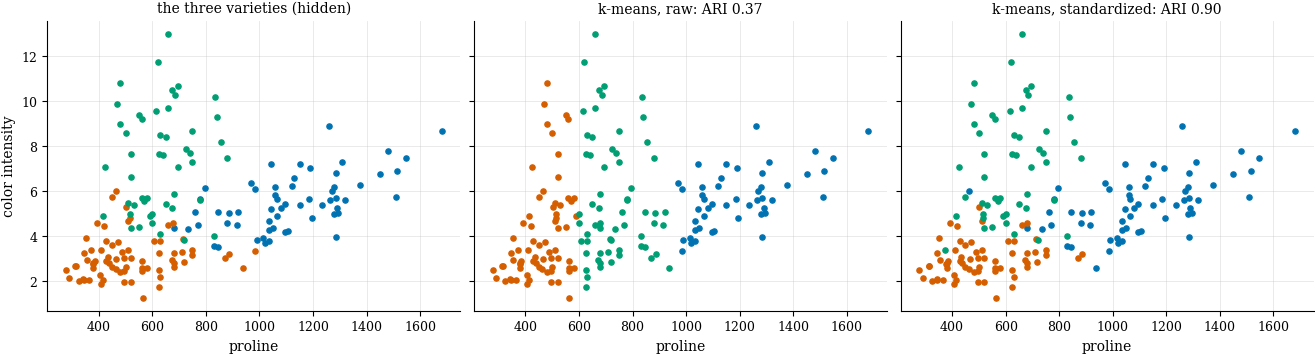

In [6]:
wine = load_wine()
Xw, yw, features = wine.data, wine.target, list(wine.feature_names)
pro, col = features.index("proline"), features.index("color_intensity")
print(f"{Xw.shape[0]} wines, {Xw.shape[1]} measurements; wines per variety: {np.bincount(yw).tolist()}")
print(f"proline from {Xw[:, pro].min():,.0f} to {Xw[:, pro].max():,.0f}; color intensity from "
      f"{Xw[:, col].min():.1f} to {Xw[:, col].max():.0f}")
sq = ((Xw[:, None, :] - Xw[None, :, :]) ** 2).sum(axis=(0, 1))     # squared differences, all pairs of wines
print(f"proline's share of all the squared distances between wines: {sq[pro] / sq.sum():.1%}")

raw = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Xw)
alone = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Xw[:, [pro]])
Xs = StandardScaler().fit_transform(Xw)
std = KMeans(n_clusters=3, n_init=10, random_state=0).fit_predict(Xs)
print(f"\nk-means on the raw numbers:  ARI {adjusted_rand_score(yw, raw):.2f}, {best_renaming(yw, raw)} of 178 "
      f"wines with their variety; same groups as proline alone: {adjusted_rand_score(raw, alone) == 1.0}")
print(f"k-means after standardizing: ARI {adjusted_rand_score(yw, std):.2f}, {best_renaming(yw, std)} of 178")
up = Xw.mean(axis=0) + Xw.std(axis=0)                  # one typical step above average (the spread StandardScaler uses)
print(f"+1 after standardizing = proline {up[pro]:,.0f}, color intensity {up[col]:.2f}")

fig, axes = plt.subplots(1, 3, figsize=(13.2, 3.6), sharey=True)
panels = ((axes[0], yw, "the three varieties (hidden)"),
          (axes[1], best_renaming(yw, raw, relabel=True), f"k-means, raw: ARI {adjusted_rand_score(yw, raw):.2f}"),
          (axes[2], best_renaming(yw, std, relabel=True), f"k-means, standardized: ARI {adjusted_rand_score(yw, std):.2f}"))
for ax, lab, title in panels:                          # colors renamed to match the varieties
    for k in range(3):
        ax.scatter(Xw[lab == k, pro], Xw[lab == k, col], s=14, color=COLORS[k])
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("proline")
axes[0].set_ylabel("color intensity")
plt.show()

The distance between two wines is almost all proline (99.8%). On the raw numbers k-means just cuts proline into
three bands, the same groups as proline alone: 125 of 178 wines with their variety (ARI 0.37). Standardized,
proline 1,061 and color intensity 7.37 both become $+1$, one typical step above average, and every measurement
gets a say: 172 of 178 (ARI 0.90). (The pictures show 2 of the 13 measurements; k-means used all 13.)

Features in **different units** (euros and years, proline and color)? Standardize. The **same unit** with
meaningful spreads (four lengths in cm)? Keep them as they are.

## 11. Check yourself: euros or thousands of euros?

200 customers are described by their yearly income (in euros) and their age (in years). You write the income in
**thousands** of euros instead.

**Predict first:** (a) do k-means' groups on the raw numbers change? (b) and if you standardize first?

In [7]:
Xc, _ = make_customers()                               # columns: income (EUR), age (years)
SCALE = [1e-3, 1.0]                                    # <-- CHANGE ME: income in thousands of euros
Xk = Xc * SCALE
before = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(Xc)
after = KMeans(n_clusters=2, n_init=10, random_state=0).fit_predict(Xk)
moved = min(np.sum(before != after), np.sum(before != 1 - after))    # group names are arbitrary
print(f"(a) raw numbers: {moved} of {len(Xc)} customers change group")
for name, X in (("as measured", Xc), (f"after SCALE = {SCALE}", Xk)):
    v = X.var(axis=0)
    print(f"    {name:26s}: income carries {v[0] / v.sum():.3%} of the variance, age {v[1] / v.sum():.3%}")
same = np.allclose(StandardScaler().fit_transform(Xc), StandardScaler().fit_transform(Xk))
print(f"(b) standardized first: identical numbers? {same}")

(a) raw numbers: 54 of 200 customers change group
    as measured               : income carries 99.998% of the variance, age 0.002%
    after SCALE = [0.001, 1.0]: income carries 5.410% of the variance, age 94.590%
(b) standardized first: identical numbers? True


**(a) Yes:** 54 of the 200 customers change group. In euros, income carries 99.998% of the variance and decides
alone; in thousands of euros its numbers shrink 1,000 times, down to the size of the ages but with a smaller
spread, and the roles flip: age now carries 94.59% of the variance and decides almost alone. Either way, one
choice of unit picks the groups. **(b) No:** euros and thousands of euros give exactly the same standardized
numbers.

## Recap & exercises

**Recap.**

* **k-means** repeats two moves, **join** the nearest center and **move** each center to the average of its
  points. Each move can only lower the cost (the WCSS), so it never goes up, and k-means always stops. On the
  eight rents it found 3.5 and 11.5, exactly where a tree that was told the areas cuts.
* It stops at **a** good answer, not always **the** best: on the twelve points 32 of 220 starts get stuck.
  **Restart** (`n_init=10`) and start cleverly (k-means++); scikit-learn's default starts only once.
* **Scoring** needs data whose groups we secretly know. Group names do not matter, so the **ARI** compares
  pairs: 1 = the same grouping, 0 = chance. It is strict and not a percentage (4 of 5 right gave 0.17).
* k-means draws **straight borders**, so it likes round groups of similar size: moons 0.23, tilted clouds 0.36,
  small beside big 0.21. Its own cost prefers its wrong answer on the moons.
* The **biggest numbers rule** the distance: a unit change flipped the four objects from shape to size, and
  proline alone decided the wine (0.37) until we standardized (0.90).
* **Use k-means when** the groups are round and of similar size, in comparable units: it is fast, on any amount
  of data.

**Exercises.**

1. In &sect;2, set `START = [12.0, 13.0]`, then `START = [0.0, 1.0]`. Do you still land on 3.5 and 11.5? How many
   passes does it take? In the second case, what happens to the center at 0 in the first pass?
2. In &sect;4, try `K_LIST = (8, 32)`. At which $K$ does the first reddish color appear in the palette? How many
   bits does each pixel need at $K = 32$?
3. In &sect;5, run `lloyd` from the start `(0, 2, 7)`: it costs 274. Follow its passes (print `passes`) and find
   the moment a center loses all its points. Why does scikit-learn reach 24 from the same start?
4. In &sect;6, with `p_stuck` from the cell: how likely are 3 random starts to all get stuck? And 5? How many
   starts do you need to be stuck less than once in a million runs?
5. In &sect;9, write the diameters in **meters** (`four * [1, 0.01]`). Which split wins now, and why?
6. In &sect;11, **predict first**: would the groups change if age were written in **months** instead of years
   (with income in euros)? Then set `SCALE = [1.0, 12.0]` and run it.
7. **Write it yourself.** Write `my_kmeans(X, K, n_starts, seed)`: draw `n_starts` random starts (K different
   points of X each, with `np.random.default_rng(seed)`), run `lloyd` from each, and keep the grouping with the
   lowest cost. On the twelve points, how often does it get stuck with `n_starts=1` and with `n_starts=10` over
   200 seeds? Compare with `KMeans(init="random", n_init=n_starts)`.